Diabetic_Retinopathy_Binary_Classification

In [1]:
import tensorflow as tf

# Set a seed to make experiments easier to reproduce.
SEED = 42
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow version:", tf.__version__)

gpus = tf.config.list_physical_devices("GPU")

if gpus:
    print("GPU available:", gpus[0].name)
else:
    print("No GPU detected. Enable a GPU in Runtime settings.")

TensorFlow version: 2.21.0
GPU available: /physical_device:GPU:0


In [2]:
%pip install -q kagglehub

import kagglehub
from pathlib import Path

dataset_path = Path(kagglehub.dataset_download(
    "sovitrath/diabetic-retinopathy-224x224-gaussian-filtered"
))

print("Dataset downloaded to:", dataset_path)

# Display folders and CSV files, without listing every image.
print("\nDataset structure:")
for item in sorted(dataset_path.rglob("*")):
    if item.is_dir() or item.suffix.lower() == ".csv":
        print(item.relative_to(dataset_path))

100%|██████████| 427M/427M [00:03<00:00, 146MB/s]

Extracting files...


Dataset downloaded to: /root/.cache/kagglehub/datasets/sovitrath/diabetic-retinopathy-224x224-gaussian-filtered/versions/2

Dataset structure:
gaussian_filtered_images
gaussian_filtered_images/gaussian_filtered_images
gaussian_filtered_images/gaussian_filtered_images/Mild
gaussian_filtered_images/gaussian_filtered_images/Moderate
gaussian_filtered_images/gaussian_filtered_images/No_DR
gaussian_filtered_images/gaussian_filtered_images/Proliferate_DR
gaussian_filtered_images/gaussian_filtered_images/Severe
train.csv


creates an image inventory without moving or modifying any images. The counts will help us check class imbalance.

In [3]:
import pandas as pd

label_map = {
    "No_DR": 0,
    "Mild": 1,
    "Moderate": 1,
    "Severe": 1,
    "Proliferate_DR": 1,
    "Proliferative_DR": 1,  # Accept this alternative spelling.
}

rows = []

for path in sorted(dataset_path.rglob("*")):
    if path.is_file() and path.suffix.lower() in {".png", ".jpg", ".jpeg"}:
        original_class = path.parent.name

        if original_class not in label_map:
            raise ValueError(f"Unexpected image folder: {original_class}")

        rows.append({
            "image_path": str(path),
            "original_class": original_class,
            "label": label_map[original_class],
        })

image_table = pd.DataFrame(rows)
assert not image_table.empty, "No images found. Check the downloaded folders."

image_table["class_name"] = image_table["label"].map({0: "No_DR", 1: "DR"})

print("Total images:", len(image_table))
print("\nOriginal categories:")
print(image_table["original_class"].value_counts())
print("\nBinary categories:")
print(image_table["class_name"].value_counts())

Total images: 3662

Original categories:
original_class
No_DR             1805
Moderate           999
Mild               370
Proliferate_DR     295
Severe             193
Name: count, dtype: int64

Binary categories:
class_name
DR       1857
No_DR    1805
Name: count, dtype: int64


Preview images and check their labels.

Displaying 3 examples from each binary category to check that images load correctly and the label mapping looks right.

No_DR images in the first row and DR images in the second, with their original categories underneath should be visible

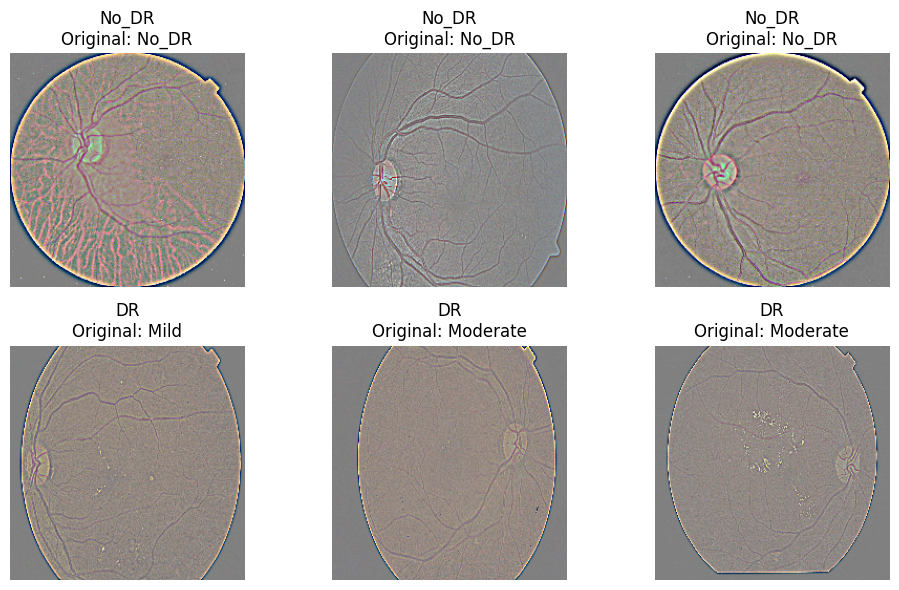

In [4]:
import matplotlib.pyplot as plt
from PIL import Image

assert set(image_table["label"]) == {0, 1}, "Both DR and No_DR must be present."

fig, axes = plt.subplots(2, 3, figsize=(10, 6))

for row, label in enumerate([0, 1]):
    class_images = image_table[image_table["label"] == label]
    samples = class_images.sample(
        n=min(3, len(class_images)), random_state=SEED
    )

    for ax in axes[row]:
        ax.axis("off")

    for ax, (_, record) in zip(axes[row], samples.iterrows()):
        with Image.open(record["image_path"]) as image:
            ax.imshow(image.convert("RGB"))

        ax.set_title(
            f'{record["class_name"]}\nOriginal: {record["original_class"]}'
        )

plt.tight_layout()
plt.show()

Check for corrupted images

Checks that every image can be opened fully and inspect image sizes. Unreadable images will be excluded from our inventory; the original files stay unchanged.

In [5]:
bad_indices = []
image_sizes = []

for index, record in image_table.iterrows():
    try:
        with Image.open(record["image_path"]) as image:
            image.load()  # Decode the complete image to detect corruption.
            image_sizes.append(image.size)

    except (OSError, ValueError) as error:
        bad_indices.append(index)
        print("Unreadable:", record["image_path"], "|", error)

# Keep a record of excluded images.
excluded_images = image_table.loc[bad_indices].copy()

image_table = image_table.drop(index=bad_indices).reset_index(drop=True)

assert not image_table.empty, "No readable images remain."

print("\nUnreadable images excluded:", len(excluded_images))
print("Readable images remaining:", len(image_table))

print("\nImage dimensions (width, height) and counts:")
print(pd.Series(image_sizes, dtype="object").value_counts())

print("\nRemaining class counts:")
print(image_table["class_name"].value_counts())


Unreadable images excluded: 0
Readable images remaining: 3662

Image dimensions (width, height) and counts:
(224, 224)    3662
Name: count, dtype: int64

Remaining class counts:
class_name
DR       1857
No_DR    1805
Name: count, dtype: int64


Step 6: Find and remove exact duplicate images

Identical images must not appear in both training and test data. Lets compare decoded image pixels, check that duplicate labels agree, and keep one copy in our inventory.

This detects exact pixel duplicates; similar images or different images from the same patient need separate consideration.

In [7]:
import hashlib

def calculate_image_hash(path):
    with Image.open(path) as image:
        image = image.convert("RGB")
        content = str(image.size).encode() + b"|" + image.tobytes()
        return hashlib.sha256(content).hexdigest()

image_table["image_hash"] = image_table["image_path"].map(
    calculate_image_hash
)

# Identify identical images assigned different binary labels.
label_counts = image_table.groupby("image_hash")["label"].nunique()
conflicting_hashes = label_counts[label_counts > 1].index

# Preserve these records for documenting our data-cleaning decision.
conflict_mask = image_table["image_hash"].isin(conflicting_hashes)
conflicting_images = image_table.loc[conflict_mask].copy()

# Exclude ALL copies with conflicting labels.
clean_images = image_table.loc[~conflict_mask].copy()

# For duplicates with consistent labels, retain one copy.
duplicate_mask = clean_images.duplicated("image_hash", keep="first")
duplicate_images = clean_images.loc[duplicate_mask].copy()
image_table = clean_images.loc[~duplicate_mask].reset_index(drop=True)

assert set(image_table["label"]) == {0, 1}, (
    "Both classes must remain after cleaning. Share the output before continuing."
)

print("Conflicting-label images excluded:", len(conflicting_images))
print("Additional duplicate copies excluded:", len(duplicate_images))
print("Unique images remaining:", len(image_table))
print("\nRemaining class counts:")
print(image_table["class_name"].value_counts())

Conflicting-label images excluded: 8
Additional duplicate copies excluded: 124
Unique images remaining: 3530

Remaining class counts:
class_name
No_DR    1796
DR       1734
Name: count, dtype: int64


Step 7: Check metadata before splitting the dataset

We need to check whether patient identifiers are available. If multiple images belong to the same patient, they should stay in the same split to prevent leakage.

In [8]:
metadata_tables = {}
csv_files = sorted(dataset_path.rglob("*.csv"))

if not csv_files:
    print("No CSV metadata files found.")
else:
    for csv_path in csv_files:
        name = str(csv_path.relative_to(dataset_path))
        metadata = pd.read_csv(csv_path)
        metadata_tables[name] = metadata

        print(f"\nFile: {name}")
        print("Columns:", metadata.columns.tolist())
        display(metadata.head(3))

print("\nExample image filenames:")
print(image_table["image_path"].map(lambda path: Path(path).name).head())


File: train.csv
Columns: ['id_code', 'diagnosis']


,id_code,diagnosis
0,000c1434d8d7,2
1,001639a390f0,4
2,0024cdab0c1e,1



Example image filenames:
0    0024cdab0c1e.png
1    00cb6555d108.png
2    0124dffecf29.png
3    01b3aed3ed4c.png
4    0369f3efe69b.png
Name: image_path, dtype: object


Step 8: Create an 80% training / 20% test split

In [9]:
from sklearn.model_selection import train_test_split

train_table, test_table = train_test_split(
    image_table,
    test_size=0.20,
    stratify=image_table["label"],
    random_state=SEED
)

train_table = train_table.reset_index(drop=True)
test_table = test_table.reset_index(drop=True)

# Verify that no identical images cross the split.
assert set(train_table["image_hash"]).isdisjoint(
    set(test_table["image_hash"])
), "Duplicate images found across training and test sets."

assert len(train_table) + len(test_table) == len(image_table)

print("Training images:", len(train_table))
print("Test images:", len(test_table))

split_counts = pd.DataFrame({
    "Training": train_table["class_name"].value_counts(),
    "Test": test_table["class_name"].value_counts()
}).fillna(0).astype(int)

display(split_counts)

Training images: 2824
Test images: 706


,Training,Test
class_name,,
No_DR,1437,359
DR,1387,347


Step 9: Create five folds for cross-validation

first fold for validation; later, compare model configurations across all five. The 706 test images remain untouched.

Stratification keeps the class proportions similar within each fold. Keep train_table unchanged because the saved fold indices refer to its rows.

In [10]:
from sklearn.model_selection import StratifiedKFold

cross_validation = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

folds = list(cross_validation.split(
    train_table,
    train_table["label"]
))

# Use the first fold while building and checking our initial model.
fit_indices, validation_indices = folds[0]

fit_table = train_table.iloc[fit_indices].copy().reset_index(drop=True)
validation_table = train_table.iloc[validation_indices].copy().reset_index(drop=True)

assert set(fit_table["image_hash"]).isdisjoint(
    set(validation_table["image_hash"])
), "Duplicate images found between fitting and validation sets."

print("Number of folds:", len(folds))
print("First-fold fitting images:", len(fit_table))
print("First-fold validation images:", len(validation_table))

display(pd.DataFrame({
    "Fitting": fit_table["class_name"].value_counts(),
    "Validation": validation_table["class_name"].value_counts()
}))

Number of folds: 5
First-fold fitting images: 2259
First-fold validation images: 565


,Fitting,Validation
class_name,,
No_DR,1149,288
DR,1110,277


Step 10: Organize images into binary-class folders

In [11]:
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

def load_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.io.decode_image(
        image, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMAGE_SIZE)

    # Normalization will be added inside the model.
    label = tf.reshape(tf.cast(label, tf.float32), [1])
    return image, label


def make_dataset(table, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((
        table["image_path"].astype(str).to_numpy(),
        table["label"].to_numpy()
    ))

    if training:
        dataset = dataset.shuffle(
            len(table), seed=SEED, reshuffle_each_iteration=True
        )

    return (
        dataset
        .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
        .batch(BATCH_SIZE)
        .prefetch(tf.data.AUTOTUNE)
    )


# These tables were created in Step 9.
train_ds = make_dataset(fit_table, training=True)
validation_ds = make_dataset(validation_table)

sample_images, sample_labels = next(iter(train_ds))

print("Image batch shape:", sample_images.shape)
print("Label batch shape:", sample_labels.shape)
print("Label mapping: 0 = No_DR, 1 = DR")

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32, 1)
Label mapping: 0 = No_DR, 1 = DR


Step 11: Build the baseline CNN

start with a small CNN as our reference model. we’ll compare it with modified architectures, augmentation, dropout, and transfer learning.

In [12]:
from tensorflow.keras import layers

def build_baseline_model():
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(*IMAGE_SIZE, 3)),
        layers.Rescaling(1.0 / 255),

        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),

        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),

        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),

        layers.GlobalAveragePooling2D(),
        layers.Dense(64, activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ], name="baseline_cnn")

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.AUC(name="auc"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall")
        ]
    )

    return model


tf.keras.utils.set_random_seed(SEED)
baseline_model = build_baseline_model()
baseline_model.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,569 (396.75 KB)

 Trainable params: 101,569 (396.75 KB)

 Non-trainable params: 0 (0.00 B)

Step 12: Train the baseline model

In [13]:
# Start with fresh weights, even if this cell is rerun.
tf.keras.utils.set_random_seed(SEED)
baseline_model = build_baseline_model()
train_ds = make_dataset(fit_table, training=True)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_auc",
    mode="max",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

baseline_history = baseline_model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=25,
    callbacks=[early_stopping],
    shuffle=False,  # Shuffling is already handled by make_dataset().
    verbose=2
)

# Evaluate the restored best weights on validation data only.
baseline_validation = baseline_model.evaluate(
    validation_ds,
    return_dict=True,
    verbose=0
)

print("Epochs completed:", len(baseline_history.history["loss"]))
display(pd.DataFrame([baseline_validation], index=["Baseline validation"]))

Epoch 1/25
71/71 - 33s - 458ms/step - accuracy: 0.6698 - auc: 0.7625 - loss: 0.6034 - precision: 0.7247 - recall: 0.5288 - val_accuracy: 0.8319 - val_auc: 0.8333 - val_loss: 0.5010 - val_precision: 0.7630 - val_recall: 0.9531
Epoch 2/25
71/71 - 4s - 60ms/step - accuracy: 0.8234 - auc: 0.8498 - loss: 0.4496 - precision: 0.7837 - recall: 0.8847 - val_accuracy: 0.8159 - val_auc: 0.8606 - val_loss: 0.4504 - val_precision: 0.7437 - val_recall: 0.9531
Epoch 3/25
71/71 - 5s - 74ms/step - accuracy: 0.8513 - auc: 0.8726 - loss: 0.4055 - precision: 0.7995 - recall: 0.9306 - val_accuracy: 0.8673 - val_auc: 0.8883 - val_loss: 0.3960 - val_precision: 0.8156 - val_recall: 0.9422
Epoch 4/25
71/71 - 4s - 60ms/step - accuracy: 0.8530 - auc: 0.8944 - loss: 0.3889 - precision: 0.8049 - recall: 0.9252 - val_accuracy: 0.8531 - val_auc: 0.8955 - val_loss: 0.3894 - val_precision: 0.7922 - val_recall: 0.9495
Epoch 5/25
71/71 - 5s - 68ms/step - accuracy: 0.8641 - auc: 0.9004 - loss: 0.3740 - precision: 0.8139 

,accuracy,auc,loss,precision,recall
Baseline validation,0.929204,0.96776,0.220112,0.95057,0.902527


Step 13: Plot the baseline’s learning curves

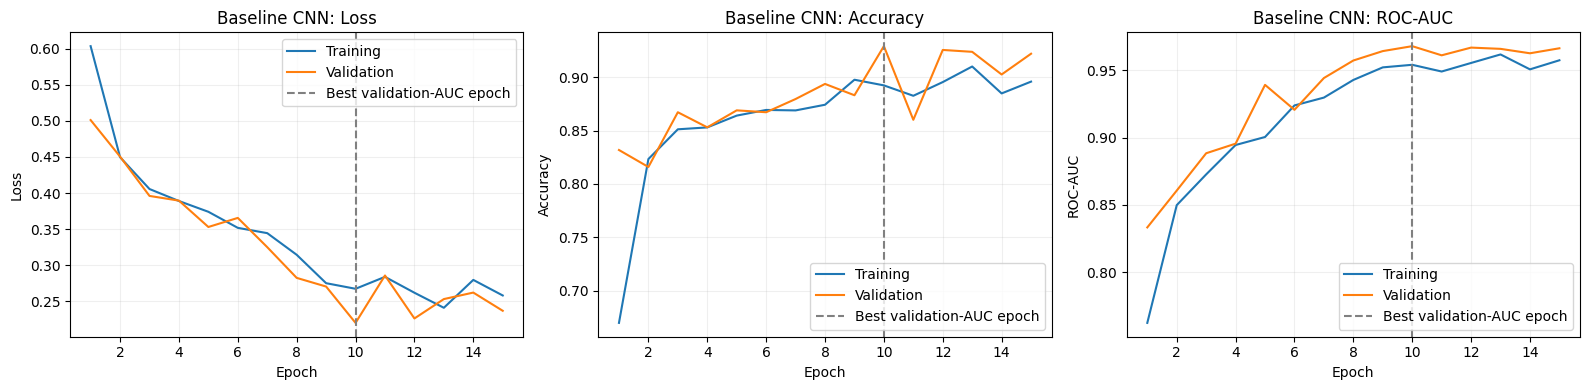

Best validation-AUC epoch: 10


In [15]:
scores = pd.DataFrame(baseline_history.history)
epochs = range(1, len(scores) + 1)
best_epoch = scores["val_auc"].idxmax() + 1

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, metric, title in zip(
    axes,
    ["loss", "accuracy", "auc"],
    ["Loss", "Accuracy", "ROC-AUC"]
):
    ax.plot(epochs, scores[metric], label="Training")
    ax.plot(epochs, scores[f"val_{metric}"], label="Validation")
    ax.axvline(
        best_epoch, color="gray", linestyle="--",
        label="Best validation-AUC epoch"
    )

    ax.set_title(f"Baseline CNN: {title}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(title)
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

print("Best validation-AUC epoch:", best_epoch)

Step 14: Define and preview data augmentation

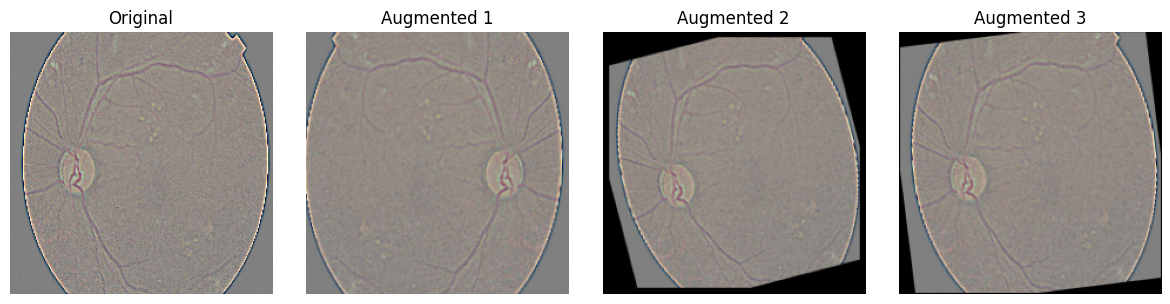

In [16]:
def make_augmentation():
    return tf.keras.Sequential([
        layers.RandomFlip("horizontal", seed=SEED),
        layers.RandomRotation(
            0.05, fill_mode="constant", fill_value=0,
            seed=SEED + 1
        ),
        layers.RandomZoom(
            0.05, fill_mode="constant", fill_value=0,
            seed=SEED + 2
        )
    ], name="augmentation")


preview_augmentation = make_augmentation()
example_images, _ = next(iter(train_ds))
original_image = example_images[:1]

fig, axes = plt.subplots(1, 4, figsize=(12, 3))

for index, ax in enumerate(axes):
    image = (
        original_image if index == 0
        else preview_augmentation(original_image, training=True)
    )

    image = tf.cast(tf.clip_by_value(image[0], 0, 255), tf.uint8)
    ax.imshow(image.numpy())
    ax.set_title("Original" if index == 0 else f"Augmented {index}")
    ax.axis("off")

plt.tight_layout()
plt.show()

Step 15: Build the modified CNN: adds augmentation, a fourth convolution/pooling block, a larger Dense layer, and dropout. Five settings are exposed for later hyperparameter tuning.

In [17]:
def build_modified_model(
    conv_blocks=4,
    base_filters=32,
    dense_units=128,
    dropout_rate=0.3,
    learning_rate=0.001
):
    model_layers = [
        tf.keras.Input(shape=(*IMAGE_SIZE, 3)),
        make_augmentation(),
        layers.Rescaling(1.0 / 255)
    ]

    for block in range(conv_blocks):
        model_layers.extend([
            layers.Conv2D(
                base_filters * (2 ** block),
                3, padding="same", activation="relu"
            ),
            layers.MaxPooling2D()
        ])

    model_layers.extend([
        layers.GlobalAveragePooling2D(),
        layers.Dense(dense_units, activation="relu"),
        layers.Dropout(dropout_rate),
        layers.Dense(1, activation="sigmoid")
    ])

    model = tf.keras.Sequential(model_layers, name="modified_cnn")

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.AUC(name="auc"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall")
        ]
    )

    return model


tf.keras.utils.set_random_seed(SEED)
modified_model = build_modified_model()
modified_model.summary()

Model: "modified_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,441 (1.61 MB)

 Trainable params: 421,441 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

Step 16: Train the modified CNN

same data split, maximum 25 epochs, and early-stopping rule as the baseline.

In [18]:
# Start fresh if this cell is rerun.
tf.keras.utils.set_random_seed(SEED)
modified_model = build_modified_model()
train_ds = make_dataset(fit_table, training=True)

modified_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_auc",
    mode="max",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

modified_history = modified_model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=25,
    callbacks=[modified_early_stopping],
    shuffle=False,
    verbose=2
)

# Evaluate the restored best-validation-AUC weights.
modified_validation = modified_model.evaluate(
    validation_ds,
    return_dict=True,
    verbose=0
)

print("Epochs completed:", len(modified_history.history["loss"]))

comparison = pd.DataFrame(
    [baseline_validation, modified_validation],
    index=["Baseline CNN", "Modified CNN"]
)

display(comparison.round(4))

Epoch 1/25
71/71 - 14s - 197ms/step - accuracy: 0.6498 - auc: 0.7476 - loss: 0.5992 - precision: 0.6815 - recall: 0.5396 - val_accuracy: 0.5345 - val_auc: 0.8304 - val_loss: 0.9819 - val_precision: 0.5921 - val_recall: 0.1625
Epoch 2/25
71/71 - 16s - 226ms/step - accuracy: 0.8521 - auc: 0.8702 - loss: 0.4167 - precision: 0.8060 - recall: 0.9207 - val_accuracy: 0.8761 - val_auc: 0.9042 - val_loss: 0.3870 - val_precision: 0.8606 - val_recall: 0.8917
Epoch 3/25
71/71 - 8s - 114ms/step - accuracy: 0.8557 - auc: 0.8950 - loss: 0.3899 - precision: 0.8141 - recall: 0.9153 - val_accuracy: 0.5451 - val_auc: 0.8702 - val_loss: 0.7952 - val_precision: 0.6724 - val_recall: 0.1408
Epoch 4/25
71/71 - 6s - 86ms/step - accuracy: 0.8685 - auc: 0.9005 - loss: 0.3700 - precision: 0.8281 - recall: 0.9243 - val_accuracy: 0.8708 - val_auc: 0.9393 - val_loss: 0.3505 - val_precision: 0.8312 - val_recall: 0.9242
Epoch 5/25
71/71 - 11s - 158ms/step - accuracy: 0.8707 - auc: 0.9184 - loss: 0.3508 - precision: 0.

,accuracy,auc,loss,precision,recall
Baseline CNN,0.9292,0.9678,0.2201,0.9506,0.9025
Modified CNN,0.9504,0.9775,0.1962,0.9770,0.9206


Step 17: Plot the modified model’s learning curves

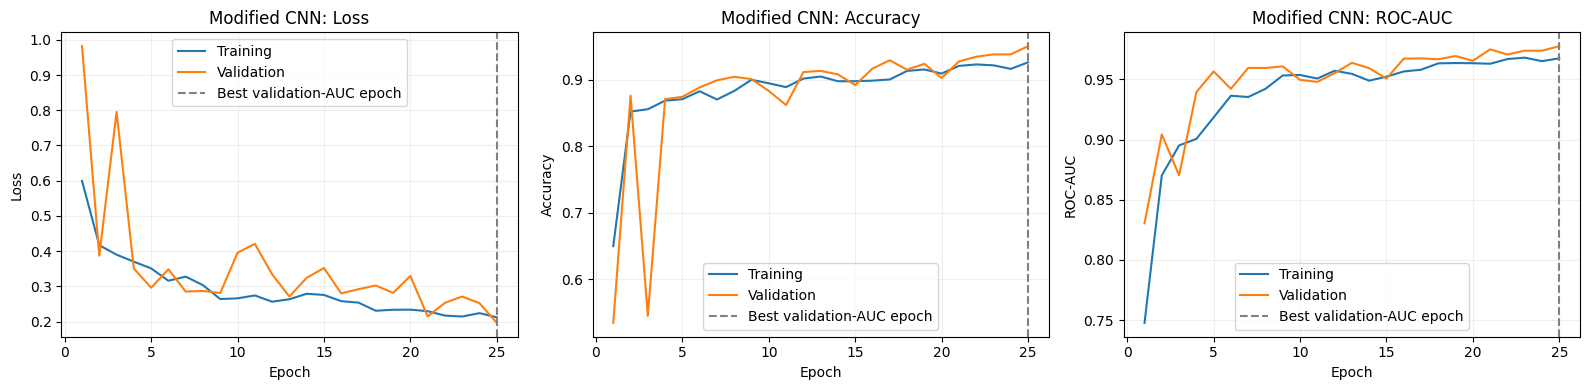

Best validation-AUC epoch: 25


In [19]:
modified_scores = pd.DataFrame(modified_history.history)
epochs = range(1, len(modified_scores) + 1)
best_epoch = modified_scores["val_auc"].idxmax() + 1

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, metric, title in zip(
    axes,
    ["loss", "accuracy", "auc"],
    ["Loss", "Accuracy", "ROC-AUC"]
):
    ax.plot(epochs, modified_scores[metric], label="Training")
    ax.plot(
        epochs, modified_scores[f"val_{metric}"],
        label="Validation"
    )
    ax.axvline(
        best_epoch, color="gray", linestyle="--",
        label="Best validation-AUC epoch"
    )

    ax.set_title(f"Modified CNN: {title}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(title)
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

print("Best validation-AUC epoch:", best_epoch)

Step 18: Build a transfer-learning model

In [20]:
def build_transfer_model(
    dense_units=128,
    dropout_rate=0.3,
    learning_rate=0.001
):
    base_model = tf.keras.applications.MobileNetV2(
        input_shape=(*IMAGE_SIZE, 3),
        include_top=False,
        weights="imagenet"
    )
    base_model.trainable = False

    inputs = tf.keras.Input(shape=(*IMAGE_SIZE, 3))
    x = make_augmentation()(inputs)
    x = layers.Rescaling(1.0 / 127.5, offset=-1)(x)

    # Keep the pretrained backbone in inference mode.
    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(dense_units, activation="relu")(x)
    x = layers.Dropout(dropout_rate)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)

    model = tf.keras.Model(
        inputs, outputs, name="transfer_mobilenetv2"
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.AUC(name="auc"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall")
        ]
    )
    return model


tf.keras.utils.set_random_seed(SEED)
transfer_model = build_transfer_model()
transfer_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "transfer_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_4 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Step 19: Train and compare the transfer-learning model.

use the same validation fold, maximum 25 epochs, and early-stopping rule as the previous models. Only the new classifier layers will train.

In [21]:
# Start with pretrained backbone weights and a fresh classifier.
tf.keras.utils.set_random_seed(SEED)
transfer_model = build_transfer_model()
train_ds = make_dataset(fit_table, training=True)

transfer_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_auc",
    mode="max",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

transfer_history = transfer_model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=25,
    callbacks=[transfer_early_stopping],
    shuffle=False,
    verbose=2
)

transfer_validation = transfer_model.evaluate(
    validation_ds,
    return_dict=True,
    verbose=0
)

print("Epochs completed:", len(transfer_history.history["loss"]))

comparison = pd.DataFrame(
    [
        baseline_validation,
        modified_validation,
        transfer_validation
    ],
    index=["Baseline CNN", "Modified CNN", "MobileNetV2"]
)

display(comparison.round(4))

Epoch 1/25
71/71 - 15s - 216ms/step - accuracy: 0.9101 - auc: 0.9594 - loss: 0.2536 - precision: 0.9104 - recall: 0.9063 - val_accuracy: 0.9257 - val_auc: 0.9823 - val_loss: 0.2142 - val_precision: 0.8904 - val_recall: 0.9675
Epoch 2/25
71/71 - 6s - 84ms/step - accuracy: 0.9500 - auc: 0.9787 - loss: 0.1632 - precision: 0.9586 - recall: 0.9387 - val_accuracy: 0.9558 - val_auc: 0.9822 - val_loss: 0.1479 - val_precision: 0.9701 - val_recall: 0.9386
Epoch 3/25
71/71 - 5s - 72ms/step - accuracy: 0.9584 - auc: 0.9849 - loss: 0.1373 - precision: 0.9678 - recall: 0.9468 - val_accuracy: 0.9540 - val_auc: 0.9825 - val_loss: 0.1565 - val_precision: 0.9466 - val_recall: 0.9603
Epoch 4/25
71/71 - 6s - 85ms/step - accuracy: 0.9535 - auc: 0.9843 - loss: 0.1437 - precision: 0.9623 - recall: 0.9423 - val_accuracy: 0.9628 - val_auc: 0.9849 - val_loss: 0.1375 - val_precision: 0.9672 - val_recall: 0.9567
Epoch 5/25
71/71 - 5s - 72ms/step - accuracy: 0.9548 - auc: 0.9858 - loss: 0.1398 - precision: 0.9693 

,accuracy,auc,loss,precision,recall
Baseline CNN,0.9292,0.9678,0.2201,0.9506,0.9025
Modified CNN,0.9504,0.9775,0.1962,0.9770,0.9206
MobileNetV2,0.9593,0.9894,0.1343,0.9601,0.9567


Step 20: Define the hyperparameter search

compare the baseline, MobileNetV2, and four modified-CNN configurations using the same five folds. select the configuration with the highest mean validation ROC-AUC.

The CNN configurations vary five hyperparameters: convolution blocks, filter counts, Dense units, dropout, and learning rate.

In [22]:
search_candidates = [
    {"name": "Baseline CNN", "family": "baseline", "params": {}},
    {"name": "MobileNetV2", "family": "transfer", "params": {}}
]

parameter_names = [
    "conv_blocks",
    "base_filters",
    "dense_units",
    "dropout_rate",
    "learning_rate"
]

# First configuration matches our existing modified CNN.
cnn_settings = [
    (4, 32, 128, 0.3, 0.001),
    (3, 16, 64, 0.2, 0.001),
    (3, 32, 128, 0.4, 0.0003),
    (4, 16, 256, 0.5, 0.0001)
]

for number, settings in enumerate(cnn_settings, start=1):
    search_candidates.append({
        "name": f"Modified CNN {number}",
        "family": "modified",
        "params": dict(zip(parameter_names, settings))
    })

CV_MAX_EPOCHS = 25
CV_PATIENCE = 5

display(pd.DataFrame([
    {"Model": candidate["name"], **candidate["params"]}
    for candidate in search_candidates
]).fillna("Not applicable"))

print("Configurations:", len(search_candidates))
print("Folds per configuration:", len(folds))
print("Total training runs:", len(search_candidates) * len(folds))

,Model,conv_blocks,base_filters,dense_units,dropout_rate,learning_rate
0,Baseline CNN,Not applicable,Not applicable,Not applicable,Not applicable,Not applicable
1,MobileNetV2,Not applicable,Not applicable,Not applicable,Not applicable,Not applicable
2,Modified CNN 1,4.0,32.0,128.0,0.3,0.001
3,Modified CNN 2,3.0,16.0,64.0,0.2,0.001
4,Modified CNN 3,3.0,32.0,128.0,0.4,0.0003
5,Modified CNN 4,4.0,16.0,256.0,0.5,0.0001


Configurations: 6
Folds per configuration: 5
Total training runs: 30


Step 21: Run five-fold cross-validation and hyperparameter tuning

Each configuration will train five fresh models, one per fold. We’ll compare their mean validation ROC-AUC. The test set remains unused, and nothing is exported.

This is the longest step. The cell prints progress for each training run.

In [23]:
import gc
import numpy as np

builders = {
    "baseline": build_baseline_model,
    "modified": build_modified_model,
    "transfer": build_transfer_model
}

cv_results = []

for candidate in search_candidates:
    for fold_number, (fit_indices, val_indices) in enumerate(folds, start=1):
        print(
            f"\n{candidate['name']} | Fold {fold_number}/{len(folds)}",
            flush=True
        )

        tf.keras.backend.clear_session()
        gc.collect()
        tf.keras.utils.set_random_seed(SEED + fold_number)

        fold_train = make_dataset(
            train_table.iloc[fit_indices], training=True
        )
        fold_validation = make_dataset(
            train_table.iloc[val_indices]
        )

        cv_model = builders[candidate["family"]](**candidate["params"])

        stopping = tf.keras.callbacks.EarlyStopping(
            monitor="val_auc",
            mode="max",
            patience=CV_PATIENCE,
            restore_best_weights=True
        )

        fold_history = cv_model.fit(
            fold_train,
            validation_data=fold_validation,
            epochs=CV_MAX_EPOCHS,
            callbacks=[stopping],
            shuffle=False,
            verbose=2
        )

        metrics = cv_model.evaluate(
            fold_validation, return_dict=True, verbose=0
        )

        cv_results.append({
            "model": candidate["name"],
            "fold": fold_number,
            "best_epoch": int(
                np.argmax(fold_history.history["val_auc"]) + 1
            ),
            "epochs_completed": len(fold_history.history["loss"]),
            **metrics
        })

        print(f"Restored-model validation AUC: {metrics['auc']:.4f}")

        del cv_model, fold_train, fold_validation, fold_history
        gc.collect()

cv_results_table = pd.DataFrame(cv_results)

assert len(cv_results_table) == len(search_candidates) * len(folds)

cv_summary = (
    cv_results_table.groupby("model")
    .agg(
        mean_auc=("auc", "mean"),
        std_auc=("auc", "std"),
        mean_accuracy=("accuracy", "mean"),
        mean_precision=("precision", "mean"),
        mean_recall=("recall", "mean"),
        mean_loss=("loss", "mean")
    )
    .sort_values("mean_auc", ascending=False)
)

display(cv_results_table.round(4))
display(cv_summary.round(4))


Baseline CNN | Fold 1/5
Epoch 1/25
71/71 - 15s - 205ms/step - accuracy: 0.5786 - auc: 0.6697 - loss: 0.6516 - precision: 0.5884 - recall: 0.4739 - val_accuracy: 0.7770 - val_auc: 0.8382 - val_loss: 0.5030 - val_precision: 0.7961 - val_recall: 0.7329
Epoch 2/25
71/71 - 14s - 192ms/step - accuracy: 0.8557 - auc: 0.8821 - loss: 0.4057 - precision: 0.8106 - recall: 0.9216 - val_accuracy: 0.8513 - val_auc: 0.9364 - val_loss: 0.3858 - val_precision: 0.7881 - val_recall: 0.9531
Epoch 3/25
71/71 - 4s - 60ms/step - accuracy: 0.8406 - auc: 0.8847 - loss: 0.4137 - precision: 0.7930 - recall: 0.9144 - val_accuracy: 0.8637 - val_auc: 0.9319 - val_loss: 0.3920 - val_precision: 0.8067 - val_recall: 0.9495
Epoch 4/25
71/71 - 6s - 86ms/step - accuracy: 0.8663 - auc: 0.9078 - loss: 0.3749 - precision: 0.8176 - recall: 0.9369 - val_accuracy: 0.8549 - val_auc: 0.9529 - val_loss: 0.3476 - val_precision: 0.7964 - val_recall: 0.9458
Epoch 5/25
71/71 - 4s - 61ms/step - accuracy: 0.8659 - auc: 0.9326 - loss: 

,model,fold,best_epoch,epochs_completed,accuracy,auc,loss,precision,recall
0,Baseline CNN,1,17,22,0.9345,0.9789,0.1896,0.9724,0.8917
1,Baseline CNN,2,24,25,0.9487,0.9725,0.2089,0.9733,0.9206
2,Baseline CNN,3,22,25,0.9292,0.9709,0.2145,0.9612,0.8921
3,Baseline CNN,4,23,25,0.9257,0.9810,0.1847,0.9097,0.9424
4,Baseline CNN,5,16,21,0.9344,0.9751,0.2133,0.9286,0.9386
5,MobileNetV2,1,11,16,0.9611,0.9889,0.1308,0.9636,0.9567
6,MobileNetV2,2,6,11,0.9062,0.9848,0.2289,0.9786,0.8267
7,MobileNetV2,3,13,18,0.9628,0.9913,0.1242,0.9673,0.9568
8,MobileNetV2,4,5,10,0.9575,0.9871,0.1405,0.9601,0.9532
9,MobileNetV2,5,16,21,0.9521,0.9873,0.1386,0.9433,0.9603


,mean_auc,std_auc,mean_accuracy,mean_precision,mean_recall,mean_loss
model,,,,,,
MobileNetV2,0.9879,0.0024,0.9479,0.9626,0.9308,0.1526
Baseline CNN,0.9757,0.0042,0.9345,0.9491,0.9171,0.2022
Modified CNN 1,0.9689,0.0058,0.9235,0.9529,0.8890,0.2450
Modified CNN 2,0.9382,0.0478,0.8116,0.9323,0.6419,0.4759
Modified CNN 3,0.9376,0.0169,0.6717,0.9822,0.3469,0.8534
Modified CNN 4,0.9216,0.0292,0.6165,0.9924,0.2226,1.0641


Step 22: Select the best configuration and train the final model

select the highest mean cross-validation ROC-AUC, then train a fresh model on all 2,824 training images.

In [24]:
# Confirm that every configuration completed all five folds.
completed_folds = cv_results_table.groupby("model")["fold"].nunique()

assert all(
    completed_folds.get(candidate["name"], 0) == len(folds)
    for candidate in search_candidates
), "Finish all cross-validation runs in Step 21 first."

# Select using cross-validation results only.
best_model_name = cv_summary["mean_auc"].idxmax()

best_candidate = next(
    candidate for candidate in search_candidates
    if candidate["name"] == best_model_name
)

winning_folds = cv_results_table[
    cv_results_table["model"] == best_model_name
]

final_epochs = max(
    1, int(np.median(winning_folds["best_epoch"]))
)

print("Selected model:", best_model_name)
print("Parameters:", best_candidate["params"] or "Model builder defaults")
print("Best epochs across folds:", winning_folds["best_epoch"].tolist())
print("Final training epochs:", final_epochs)
display(cv_summary.loc[[best_model_name]].round(4))

# Rebuild from scratch; transfer learning starts from ImageNet weights.
tf.keras.backend.clear_session()
gc.collect()
tf.keras.utils.set_random_seed(SEED)

final_model = builders[best_candidate["family"]](
    **best_candidate["params"]
)

full_train_ds = make_dataset(train_table, training=True)

final_history = final_model.fit(
    full_train_ds,
    epochs=final_epochs,
    shuffle=False,
    verbose=2
)

print("Final model trained on", len(train_table), "images.")

Selected model: MobileNetV2
Parameters: Model builder defaults
Best epochs across folds: [11, 6, 13, 5, 16]
Final training epochs: 11


,mean_auc,std_auc,mean_accuracy,mean_precision,mean_recall,mean_loss
model,,,,,,
MobileNetV2,0.9879,0.0024,0.9479,0.9626,0.9308,0.1526


Epoch 1/11
89/89 - 11s - 123ms/step - accuracy: 0.9210 - auc: 0.9708 - loss: 0.2108 - precision: 0.9248 - recall: 0.9135
Epoch 2/11
89/89 - 6s - 67ms/step - accuracy: 0.9554 - auc: 0.9834 - loss: 0.1465 - precision: 0.9695 - recall: 0.9387
Epoch 3/11
89/89 - 5s - 57ms/step - accuracy: 0.9547 - auc: 0.9836 - loss: 0.1464 - precision: 0.9687 - recall: 0.9380
Epoch 4/11
89/89 - 7s - 84ms/step - accuracy: 0.9554 - auc: 0.9851 - loss: 0.1390 - precision: 0.9646 - recall: 0.9438
Epoch 5/11
89/89 - 5s - 58ms/step - accuracy: 0.9543 - auc: 0.9865 - loss: 0.1350 - precision: 0.9611 - recall: 0.9452
Epoch 6/11
89/89 - 6s - 69ms/step - accuracy: 0.9589 - auc: 0.9854 - loss: 0.1354 - precision: 0.9711 - recall: 0.9445
Epoch 7/11
89/89 - 9s - 105ms/step - accuracy: 0.9582 - auc: 0.9898 - loss: 0.1182 - precision: 0.9697 - recall: 0.9445
Epoch 8/11
89/89 - 6s - 68ms/step - accuracy: 0.9575 - auc: 0.9892 - loss: 0.1229 - precision: 0.9689 - recall: 0.9438
Epoch 9/11
89/89 - 10s - 112ms/step - accurac

Step 23: Evaluate the final model on the reserved test set

23/23 ━━━━━━━━━━━━━━━━━━━━ 9s 302ms/step


,accuracy,auc,loss,precision,recall,f1,specificity
MobileNetV2,0.9221,0.9878,0.2067,0.8763,0.9798,0.9252,0.8663


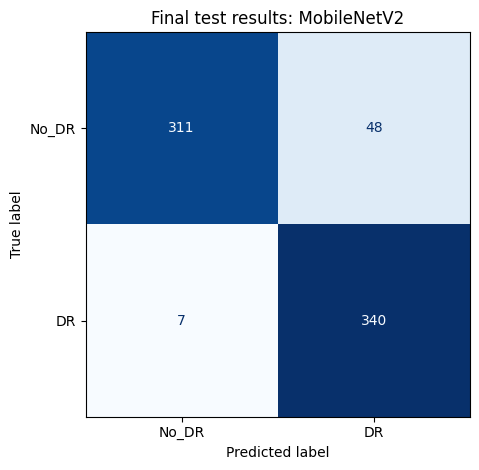

DR images missed (false negatives): 7
No_DR images incorrectly classified as DR (false positives): 48


In [25]:
from sklearn import metrics

test_ds = make_dataset(test_table, training=False)
y_test = test_table["label"].to_numpy()

# Predict once, preserving the test-table order.
test_probabilities = final_model.predict(test_ds, verbose=1).ravel()

assert len(test_probabilities) == len(y_test)
assert np.isfinite(test_probabilities).all(), "Predictions contain invalid values."

threshold = 0.5
test_predictions = (test_probabilities > threshold).astype(int)

test_metrics = {
    "accuracy": metrics.accuracy_score(y_test, test_predictions),
    "auc": metrics.roc_auc_score(y_test, test_probabilities),
    "loss": metrics.log_loss(y_test, test_probabilities, labels=[0, 1]),
    "precision": metrics.precision_score(
        y_test, test_predictions, zero_division=0
    ),
    "recall": metrics.recall_score(
        y_test, test_predictions, zero_division=0
    ),
    "f1": metrics.f1_score(y_test, test_predictions, zero_division=0)
}

confusion = metrics.confusion_matrix(
    y_test, test_predictions, labels=[0, 1]
)
tn, fp, fn, tp = confusion.ravel()
test_metrics["specificity"] = tn / (tn + fp)

display(pd.DataFrame(
    [test_metrics], index=[best_model_name]
).round(4))

metrics.ConfusionMatrixDisplay(
    confusion_matrix=confusion,
    display_labels=["No_DR", "DR"]
).plot(cmap="Blues", values_format="d", colorbar=False)

plt.title(f"Final test results: {best_model_name}")
plt.tight_layout()
plt.show()

print("DR images missed (false negatives):", fn)
print("No_DR images incorrectly classified as DR (false positives):", fp)